# Неделя 13. Gradient Boosting, XGBoost и LightGBM: последовательное исправление ошибок

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** реализовать первые шаги boosting, запустить три реальные библиотеки, выбрать параметры на общих folds и подготовить честный промежуточный проект.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_13_boosting_tuning'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'diabetes_raw.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (331, 10), 'sealed_test': (111, 10)}


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
sample_id,,,,,,,,,,
16,47,1,30.3,109.0,207,100.2,70.0,3.00,5.2149,98
408,66,1,21.7,126.0,212,127.8,45.0,4.71,5.2781,101
432,51,1,31.5,93.0,231,144.0,49.0,4.70,5.2523,117


## 1. EDA и план эксперимента

Цель непрерывная: используем RMSE как основной критерий, MAE как дополнение.
Набор небольшой и учебный; сравнение библиотек здесь не является общим рейтингом
скорости или качества. Зафиксируем одинаковые folds и малые сетки параметров.


,count,mean,std,min,25%,50%,75%,max
age,331.0,48.80,12.79,19.00,39.0,50.00,59.00,79.00
sex,331.0,1.47,0.50,1.00,1.0,1.00,2.00,2.00
bmi,331.0,26.59,4.38,18.10,23.5,25.90,29.50,41.30
bp,331.0,95.02,13.91,62.00,84.0,93.00,105.00,133.00
s1,331.0,189.55,34.98,110.00,163.5,187.00,209.00,301.00
s2,331.0,115.47,30.85,41.60,94.8,113.00,133.90,242.40
s3,331.0,49.63,12.79,22.00,41.0,48.00,57.00,99.00
s4,331.0,4.09,1.31,2.00,3.0,4.00,5.00,9.09
s5,331.0,4.66,0.53,3.26,4.3,4.63,5.02,6.11
s6,331.0,92.05,11.46,58.00,84.0,92.00,99.00,124.00


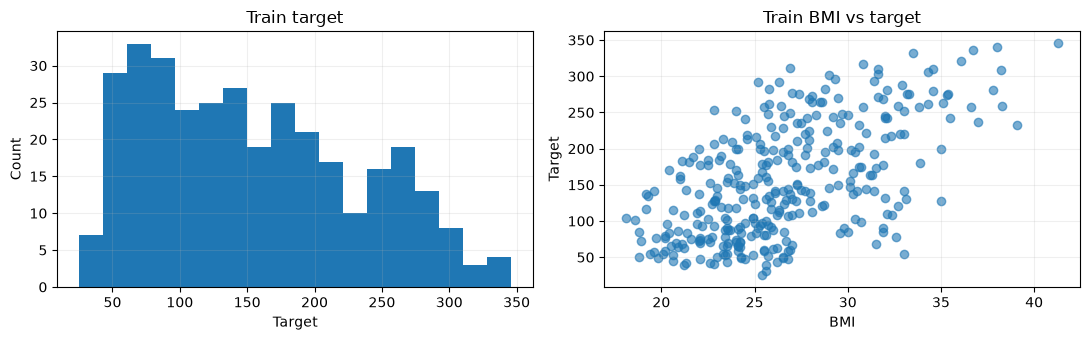

In [3]:
display(X_train.describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
y_train.hist(bins=18, ax=axes[0]); axes[0].set(title="Train target", xlabel="Target", ylabel="Count")
axes[1].scatter(X_train.bmi, y_train, alpha=0.6)
axes[1].set(title="Train BMI vs target", xlabel="BMI", ylabel="Target")
plt.tight_layout(); plt.show()
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED + 1)
assert set(X_fit.index).isdisjoint(X_val.index)


## 2. Boosting для squared error

Начинаем с константы $F_0(x)=\bar y$. Для функции $\frac12(y-F)^2$
отрицательный градиент по $F$ — остаток $r=y-F$.
$$h_m\leftarrow\mathrm{fit}(X,r_m),\qquad
F_m(x)=F_{m-1}(x)+\eta h_m(x).$$

В отличие от bagging, деревья обучаются **последовательно**, каждое исправляет
текущие ошибки. Ниже обучаем короткий ансамбль вручную на fit и наблюдаем validation.


In [4]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
base_value = y_fit.mean()
train_prediction = np.full(len(X_fit), base_value)
val_prediction = np.full(len(X_val), base_value)
weak_trees, history = [], []
learning_rate = 0.15
for iteration in range(40):
    residual = y_fit.to_numpy() - train_prediction
    tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=8, random_state=SEED + iteration)
    tree.fit(X_fit, residual)
    train_prediction += learning_rate * tree.predict(X_fit)
    val_prediction += learning_rate * tree.predict(X_val)
    weak_trees.append(tree)
    history.append({"round": iteration+1,
                    "fit_RMSE": np.sqrt(mean_squared_error(y_fit, train_prediction)),
                    "validation_RMSE": np.sqrt(mean_squared_error(y_val, val_prediction))})
manual_history = pd.DataFrame(history)
assert manual_history.fit_RMSE.iloc[-1] < manual_history.fit_RMSE.iloc[0]
display(manual_history.head())


,round,fit_RMSE,validation_RMSE
0,1,73.838411,71.337070
1,2,69.780022,68.815763
2,3,66.217302,66.102833
3,4,63.462043,65.052818
4,5,60.931795,63.116934


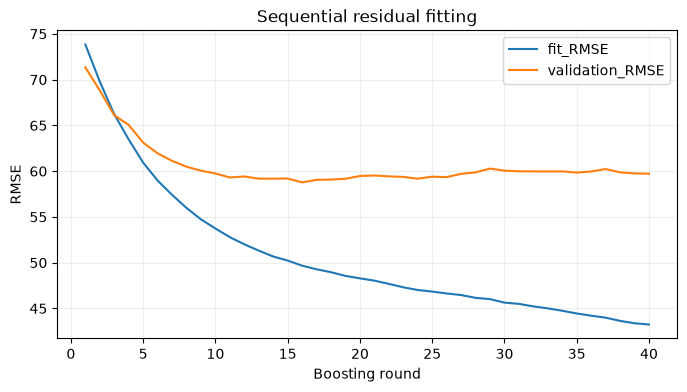

Прогноз воспроизведён суммой деревьев; max error: 1.7053025658242404e-13


In [5]:
manual_history.set_index("round").plot()
plt.xlabel("Boosting round"); plt.ylabel("RMSE"); plt.title("Sequential residual fitting")
plt.show()
reconstructed = base_value + learning_rate * sum(tree.predict(X_val) for tree in weak_trees)
assert np.allclose(reconstructed, val_prediction)
print("Прогноз воспроизведён суммой деревьев; max error:", np.max(abs(reconstructed-val_prediction)))


## 3. Три реальные реализации

Импортируем именно `xgboost` и `lightgbm`; sklearn-модель не выдаётся за эти
библиотеки. Отсутствующая зависимость — ошибка окружения, которую исправляют
установкой requirements до запуска. Все варианты CPU, `n_jobs=1`.

scikit-learn GradientBoosting — прозрачный классический baseline.
XGBoost добавляет собственную систему оптимизации и регуляризации.
LightGBM использует histogram-алгоритмы и leaf-wise рост; `num_leaves` и
`min_child_samples` помогают ограничивать сложность.


In [6]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from time import perf_counter
print("XGBoost", xgb.__version__, "| LightGBM", lgb.__version__)
candidates = {
    "mean baseline": DummyRegressor(),
    "sklearn GB": GradientBoostingRegressor(n_estimators=80, learning_rate=0.05,
                                             max_depth=2, random_state=SEED),
    "XGBoost": xgb.XGBRegressor(n_estimators=80, learning_rate=0.05, max_depth=2,
         objective="reg:squarederror", tree_method="hist", random_state=SEED, n_jobs=1),
    "LightGBM": lgb.LGBMRegressor(n_estimators=80, learning_rate=0.05, num_leaves=7,
         min_child_samples=12, verbosity=-1, force_col_wise=True, random_state=SEED, n_jobs=1)}
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)


XGBoost 3.4.1 | LightGBM 4.7.0


## 4. Одинаковые folds, одинаковая метрика

Положительный RMSE получается сменой знака score. Измеряем фактическое время
этого запуска, но не делаем вывод о скорости библиотеки в целом: overhead
доминирует на таком небольшом наборе.


In [7]:
baseline_rows = []
for name, estimator in candidates.items():
    started = perf_counter()
    scores = -cross_val_score(estimator, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
    baseline_rows.append({"model": name, "CV_RMSE": scores.mean(),
                          "fold_SD": scores.std(), "seconds": perf_counter()-started})
display(pd.DataFrame(baseline_rows).round(3))


,model,CV_RMSE,fold_SD,seconds
0,mean baseline,78.288,1.935,0.010
1,sklearn GB,59.801,3.378,0.117
2,XGBoost,59.359,3.490,0.036
3,LightGBM,60.897,3.098,0.028


## 5. Небольшой и объявленный заранее бюджет подбора

У каждой библиотеки четыре комбинации: два значения learning rate × два уровня
сложности. Число кандидатов одинаково, смысл параметров роста деревьев отличается.
Не расширяем сетку после просмотра test. CV-оценка победителя оптимистична из-за
выбора из нескольких вариантов; независимый test нужен для итогового отчёта.


In [8]:
grids = {
    "sklearn GB": {"learning_rate": [0.03, 0.1], "max_depth": [1, 2]},
    "XGBoost": {"learning_rate": [0.03, 0.1], "max_depth": [1, 2]},
    "LightGBM": {"learning_rate": [0.03, 0.1], "num_leaves": [3, 7]}}
searches, tuning_rows = {}, []
for name, params in grids.items():
    search = GridSearchCV(candidates[name], params, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({"family": name, "best_CV_RMSE": -search.best_score_,
                        "parameters": search.best_params_})
tuning_table = pd.DataFrame(tuning_rows).sort_values("best_CV_RMSE")
display(tuning_table)
chosen_name = tuning_table.iloc[0]["family"]
final_model = searches[chosen_name].best_estimator_
print("Зафиксирована модель по CV:", chosen_name)


,family,best_CV_RMSE,parameters
1,XGBoost,58.603068,"{'learning_rate': 0.1, 'max_depth': 1}"
0,sklearn GB,58.751748,"{'learning_rate': 0.1, 'max_depth': 1}"
2,LightGBM,58.826664,"{'learning_rate': 0.1, 'num_leaves': 3}"


Зафиксирована модель по CV: XGBoost


## 6. Early stopping: отдельный опыт на fit/validation

Early stopping выбирает число boosting rounds по validation. **Нельзя передавать
X_test в eval_set.** Демонстрация ниже не заменяет CV-план выше; её результаты
помогают понять алгоритм. Для финального проекта можно заранее выбрать один
протокол и описать, как после early stopping переобучается модель.


In [9]:
early_xgb = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=2,
    early_stopping_rounds=20, objective="reg:squarederror", eval_metric="rmse",
    tree_method="hist", random_state=SEED, n_jobs=1)
early_xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
early_lgb = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=7,
    min_child_samples=12, verbosity=-1, force_col_wise=True, random_state=SEED, n_jobs=1)
early_lgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric="rmse",
              callbacks=[lgb.early_stopping(20, verbose=False)])
print("XGBoost rounds selected:", early_xgb.best_iteration + 1)
print("LightGBM rounds selected:", early_lgb.best_iteration_)
assert 1 <= early_xgb.best_iteration + 1 <= 400
assert 1 <= early_lgb.best_iteration_ <= 400


XGBoost rounds selected: 41
LightGBM rounds selected: 54


/tmp/tech-orda-ml-qa/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


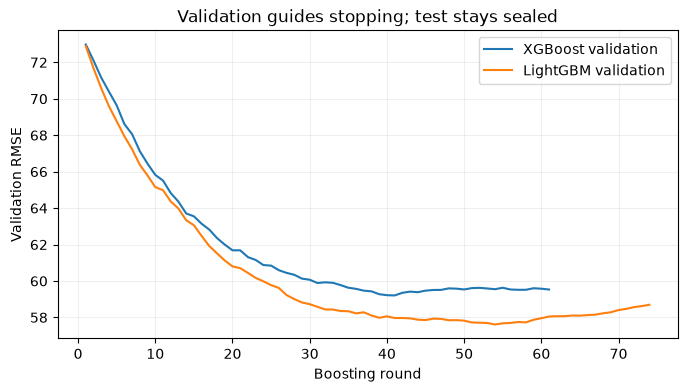

In [10]:
xgb_curve = early_xgb.evals_result()["validation_0"]["rmse"]
lgb_curve = early_lgb.evals_result_["valid_0"]["rmse"]
plt.plot(np.arange(1, len(xgb_curve)+1), xgb_curve, label="XGBoost validation")
plt.plot(np.arange(1, len(lgb_curve)+1), lgb_curve, label="LightGBM validation")
plt.xlabel("Boosting round"); plt.ylabel("Validation RMSE")
plt.title("Validation guides stopping; test stays sealed"); plt.legend(); plt.show()


## 7. Отчёт о финальном holdout

До этой ячейки определены семейство, параметры и метрики. Проверяем только
выбранную модель и заранее объявленный baseline. Test не используется для
нового подбора после получения результата.


In [11]:
final_prediction = final_model.predict(X_test)
mean_prediction = DummyRegressor().fit(X_train, y_train).predict(X_test)
report = []
for name, prediction in [("mean baseline", mean_prediction), (chosen_name, final_prediction)]:
    report.append({"model": name, "MAE": mean_absolute_error(y_test, prediction),
                   "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                   "R2": r2_score(y_test, prediction)})
display(pd.DataFrame(report).round(3))
assert final_prediction.shape == y_test.shape and np.isfinite(final_prediction).all()


,model,MAE,RMSE,R2
0,mean baseline,65.527,74.881,-0.014
1,XGBoost,42.385,53.024,0.492


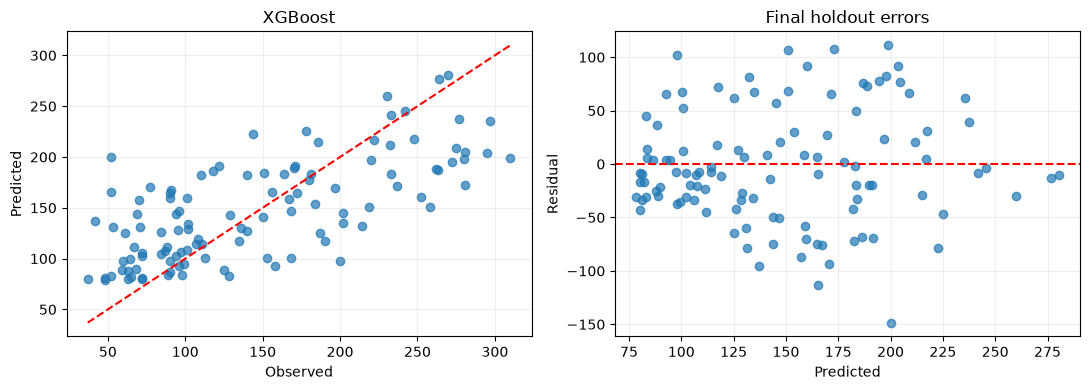

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, final_prediction, alpha=0.7)
bounds = [min(y_test.min(), final_prediction.min()), max(y_test.max(), final_prediction.max())]
axes[0].plot(bounds, bounds, "r--"); axes[0].set(xlabel="Observed", ylabel="Predicted", title=chosen_name)
axes[1].scatter(final_prediction, y_test.to_numpy()-final_prediction, alpha=0.7)
axes[1].axhline(0, color="r", ls="--"); axes[1].set(xlabel="Predicted", ylabel="Residual", title="Final holdout errors")
plt.tight_layout(); plt.show()


## 8. Промежуточный проект: таблица доказательств

Создайте краткую карточку эксперимента. Она должна позволить другому студенту
воспроизвести результат и понять пределы вывода. Различайте измеренные метрики
и гипотезы о будущем применении. Репозиторий исходной библиотеки — источник кода,
но он не заменяет описание вашего split и трансформаций.


In [13]:
experiment_card = {
    "task": "Educational diabetes regression, no clinical deployment",
    "target": "target", "excluded_columns": ["sample_id", "target"],
    "train_rows": len(X_train), "test_rows": len(X_test), "seed": SEED,
    "selection": "3-fold CV RMSE on training partition",
    "winner": chosen_name, "parameters": searches[chosen_name].best_params_,
    "limitation": "Small historic teaching dataset; no external/site/time validation"}
display(pd.Series(experiment_card))
assert experiment_card["train_rows"] + experiment_card["test_rows"] == len(df)


task                Educational diabetes regression, no clinical d...
target                                                         target
excluded_columns                                  [sample_id, target]
train_rows                                                        331
test_rows                                                         111
seed                                                               42
selection                        3-fold CV RMSE on training partition
winner                                                        XGBoost
parameters                     {'learning_rate': 0.1, 'max_depth': 1}
limitation          Small historic teaching dataset; no external/s...
dtype: object

## Контрольные вопросы

Почему обучаемое на остатках дерево не является самостоятельным прогнозом цели?
Почему learning rate и число деревьев связаны? В чём разница между OOB и early stopping?
Почему маленький Wine/Diabetes не позволяет выбрать «лучшую библиотеку вообще»?

Источники: [Friedman, Greedy Function Approximation](https://jerryfriedman.su.domains/ftp/trebst.pdf),
[XGBoost paper](https://arxiv.org/abs/1603.02754),
[XGBoost sklearn interface](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html),
[LightGBM paper](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html),
[LightGBM Python introduction](https://lightgbm.readthedocs.io/en/stable/Python-Intro.html).
